# Lab 6: Graphical Models

Welcome to the advanced Machine Learning Course.

The objective of this lab session is to code yout own Graphical Lasso and Nodewise regression.

Please put **"ML - MDS - TD6"** in the mail subject or I might lose your work (which means 0) and send it to ludovic.trautmann@inria.fr

Please label your notebook **"L6_familyname1_familyname2.ipynb"**.

Make sure to put comments in your code. **Raw numerical results or plots without comments will have almost no value in the grading. Please make sure to comment yout results.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_context('poster')
sns.set_color_codes()
plot_kwds = {'alpha' : 0.25, 's' : 80, 'linewidths':0}
from tqdm import tqdm
import networkx as nx
import scipy

# Graphical Lasso

Implement your own Graphical Lasso

In [2]:
class my_GLasso():
    
    def __init__(self, lambd=0.01, rho=0.01, max_iter = 60):
        '''
        Parameters:
        lambd : float
            Penalization parameter selected.
        rho: float>0

        Attributes:
        
        covariance_ : numpy.ndarray, shape (n_features, n_features)
            Estimated covariance matrix.
        precision_ : numpy.ndarray, shape (n_features, n_features)
            Estimated precision matrix (inverse covariance).
        '''
        self.covariance_ = None
        self.precision_ = None
        self.lambd = lambd
        self.rho = rho
        self.max_iter = max_iter
        
    def fit(self, X):
        """ Fits the GraphicalLasso model to X.
        
        Parameters:
        -----------
        X: (n, p) np.array
            Data matrix
        
        Returns:
        -----
        self
        """         
        # TODO
        n, p = X.shape
        S = (X.T @ X)/n
        Z = np.identity(p)
        U = np.zeros((p, p))
        
        for _ in range(self.max_iter) :
            A = self.rho * (Z - U) - S
            eigenvalues, Q = np.linalg.eigh(A)
            new_eigenvalues = (eigenvalues + np.sqrt(eigenvalues**2 + 4*self.rho))/(2*self.rho)
            self.precision_ = Q @ np.diag(new_eigenvalues) @ Q.T
            
            Z = np.sign(self.precision_ + U)*np.maximum(np.abs(self.precision_ + U) - self.lambd/self.rho, 0)
            
            U = U + self.precision_ - Z
            
        return self.precision_
            
        

c:\Users\jeann\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\covariance\_graph_lasso.py:197: ConvergenceWarning: graphical_lasso: did not converge after 100 iteration: dual gap: -2.033e-04
  warnings.warn(


vmax=3.082013603025085


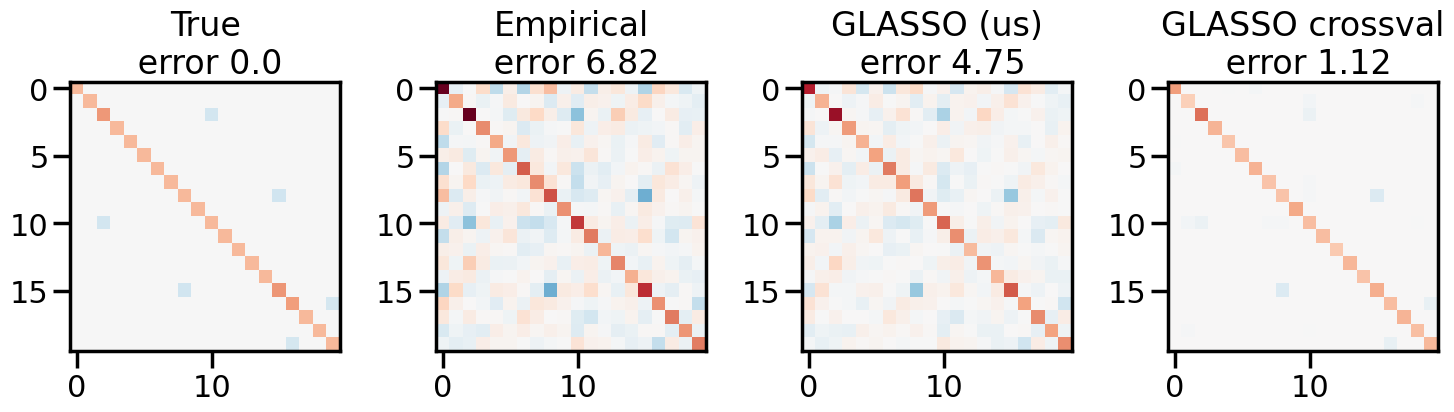

In [3]:
#Compare methods of estimating the covariance matrix in low-sample regime
n_samples = 60
n_features = 20

# Simulate data (multivariate gaussian)
from sklearn.datasets import make_sparse_spd_matrix
rng = np.random.RandomState(1)
prec = make_sparse_spd_matrix(n_features, alpha=.98, smallest_coef=.4, largest_coef=.7, random_state=rng)
cov = np.linalg.inv(prec)
mean = np.zeros(n_features)
data = np.random.multivariate_normal(mean, cov, n_samples)
err = np.linalg.norm(prec - prec)

prec_empirical = np.linalg.inv(np.dot(data.T, data) / n_samples)
err_empirical = np.linalg.norm(prec - prec_empirical)

# Scikit-learn Graphical Lasso with cross validation
from sklearn.covariance import GraphicalLassoCV
#TODO
prec_glassocv = GraphicalLassoCV().fit(data).precision_
err_glassocv = np.linalg.norm(prec - prec_glassocv)

# Graphical Lasso estimation using our implementation
#TODO
prec_glasso = my_GLasso().fit(data)
err_glasso = np.linalg.norm(prec - prec_glasso)

# Visual comparison
titles = ["True", "Empirical", "GLASSO (us)", "GLASSO crossval"]
imgs = [prec, prec_empirical, prec_glasso, prec_glassocv]
errors = [err, err_empirical, err_glasso, err_glassocv]
vmax = np.max([np.max(prec), np.max(prec_empirical), np.max(prec_glasso), np.max(prec_glassocv)])
print(f"{vmax=}")

ncols = len(titles)
fig, axes = plt.subplots(1, ncols, figsize=(15, 5))
for idx, ax in enumerate(axes.flatten()):
    img = imgs[idx]
    error = np.around(errors[idx], decimals=2)
    title = titles[idx] + f'\n error {error}'
    ax.imshow(img, vmin=-vmax, vmax=vmax, interpolation='nearest', cmap=plt.cm.RdBu_r)
    ax.set_title(title)
fig.tight_layout()

régler les paramètres du modele sklearn ??

# Nodewise Regression

Fill in the following class that implements the nodewise regression algorithm to estimate a graphical model structure. You can use `LassoCV` for the regressions.

In [43]:
from sklearn.linear_model import LassoCV

class my_nodewise_regression():
    
    def __init__(self, rule='AND', eps=1e-8):
        '''
        Parameters:
        
        rule: {"OR", "AND"}
        eps: Threshold for checking if beta_ij = 0
        
        Attributes:
        
        graph_structure_ : numpy.ndarray, shape (n_features, n_features)
            Estimated adjacancy matrix.        
        '''
        self.graph_structure_ = None
        self.rule = rule
        self.eps = eps
        
    def fit(self, X):
        """ Fit the model to X.
        
        Parameters:
        -----------
        X: (n, p) np.array
            Data matrix
        
        Returns:
        -----
        Update self.graph_structure_
        """         
        #TODO
        n, p = X.shape
        self.graph_structure_ = np.zeros((p, p))
        S = []
        
        for j in range(p) :
            D_ = np.delete(X, j, axis=1)
            d = X[:, j]
            beta = LassoCV(cv=5,max_iter=10000,tol=1e-4).fit(D_, d).coef_
            S.append([i for i in range(p) if i!= j and np.abs(beta[i if i < j else i-1]) > self.eps])
        
        if self.rule == "AND" :
            for j in range(p) :
                for k in range(p) :
                    if (k in S[j] ) and (j in S[k]) : 
                        self.graph_structure_[j, k] = 1 
        if self.rule == "OR" :
            for j in range(p) :
                for k in range(p) :
                    if (k in S[j] ) or (j in S[k] ): 
                        self.graph_structure_[j, k] = 1  
        
        return self.graph_structure_
        

## Plots

In [5]:
np.random.seed(1)
n = 5000
p = 6
epsilon=1e-1
X = np.random.randn(n, p)
X.T[1] += X.T[0]
X.T[2] += X.T[1]
real_graph_structure = np.zeros((p, p))
real_graph_structure[0,1] = 1
real_graph_structure[1,0] = 1
real_graph_structure[1,2] = 1
real_graph_structure[2,1] = 1

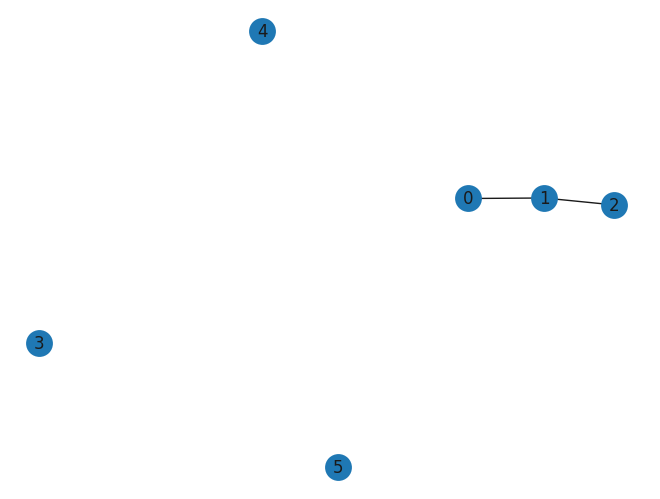

In [6]:
nx_real = nx.from_numpy_array(real_graph_structure.T)
#We draw the initial structure
nx.draw(nx_real, with_labels=True)

We notice that the initial graph is **poorly connected**, there are a lot of conditional independances between the components.

When we will reconstruct the graph with the predicted value of the precision matrix, **we expect higher values for the conditional correlation between nodes 0, 1 and 2**. 

However, based on what we saw before, we must expect a complete graph if we dont specify a minimum weight for the edges to be taken into account.

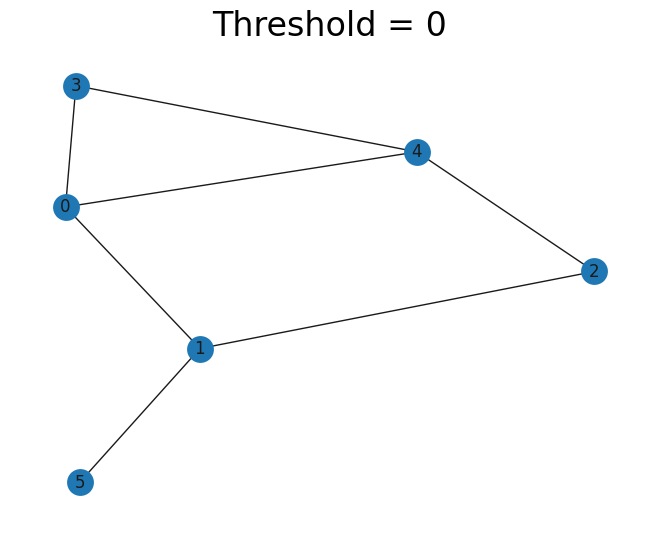

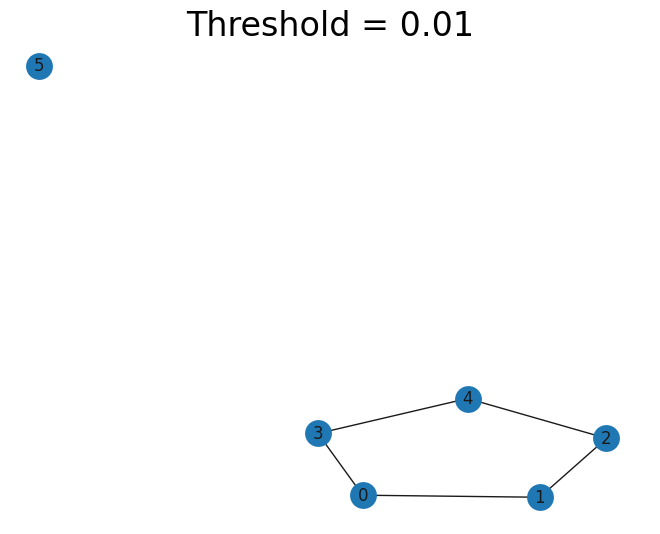

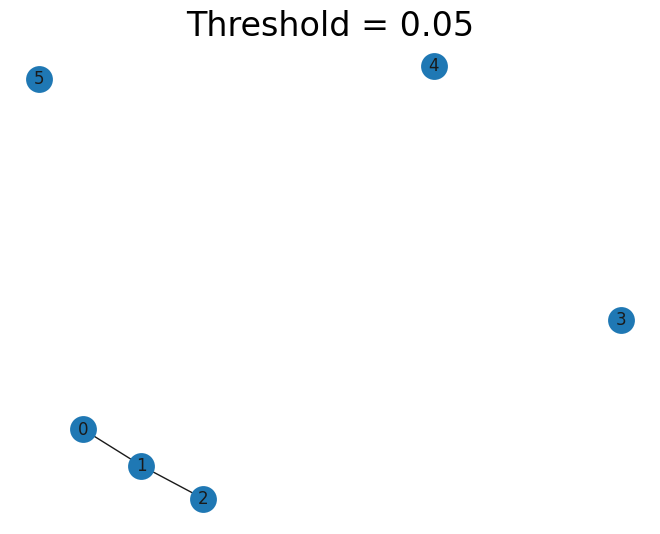

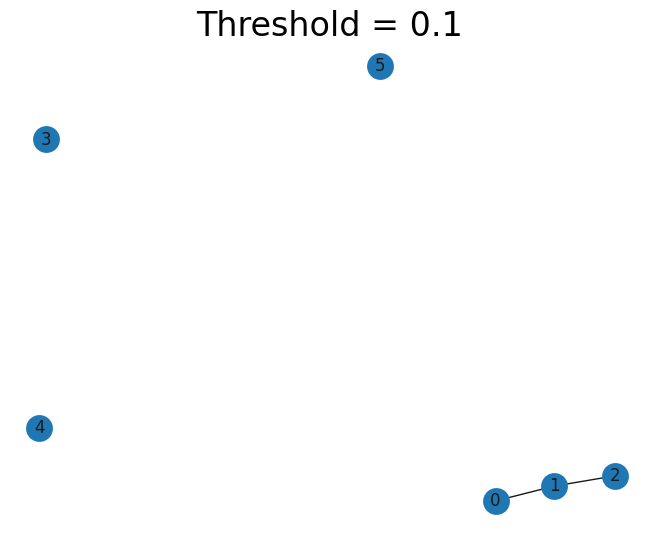

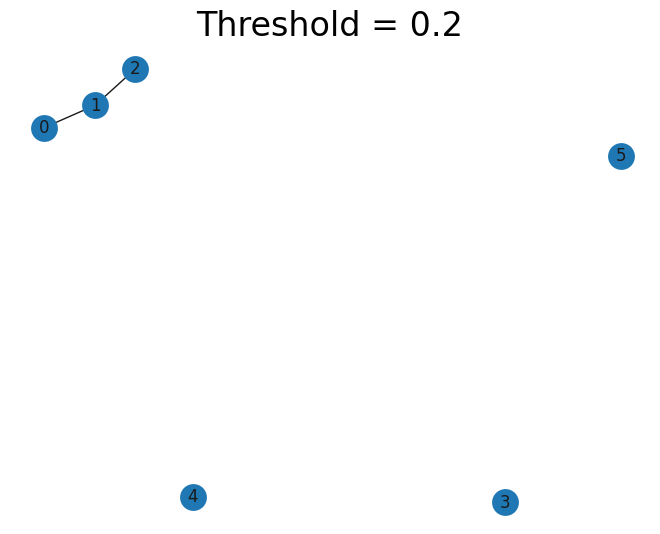

In [7]:
#TODO : plot the reconstructed graph with GLASSO using different thresholds. Comment the impact of the choice of the threshold

model = GraphicalLassoCV()
model.fit(X)

precision = model.precision_


thresholds = [0, 0.01, 0.05, 0.1, 0.2]


for threshold in thresholds:
    adjacency = (np.abs(precision) > threshold).astype(int)
    np.fill_diagonal(adjacency, 0)
    G = nx.from_numpy_array(adjacency)

    nx.draw(G,with_labels=True)
    plt.title(f"Threshold = {threshold}")

    plt.show()

**Comments:** With the 0 threshold, the graph is fully connected, as expected. With the 0.01 threshold, points 0,1,2,3,4 are connected, but not point 5. Above threshold 0.05, points 0, 1 and 2 are connected and points 3, 4 and 5 are left alone. The higher the threshold, the sparser the graph. 

## Plots nodewise regression

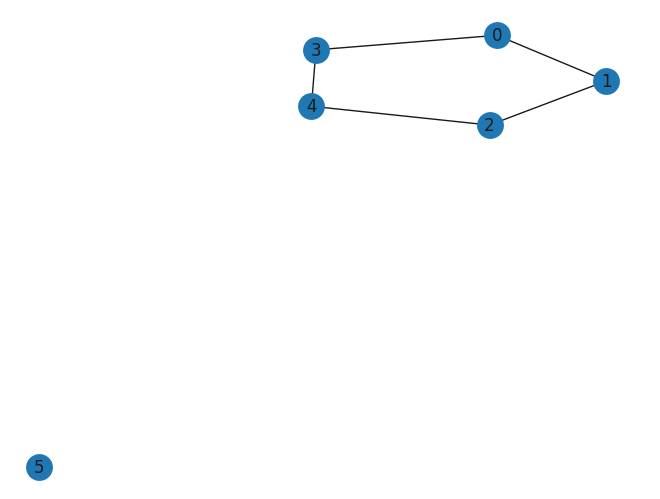

In [15]:
#TODO : plot the reconstructed graph with nodewise regression using the rule OR
or_graph_structure = my_nodewise_regression(rule = "OR").fit(X)

nx_real = nx.from_numpy_array(or_graph_structure.T)
#We draw the initial structure
nx.draw(nx_real, with_labels=True)

array([[0., 1., 0., 0., 0., 0.],
       [1., 0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

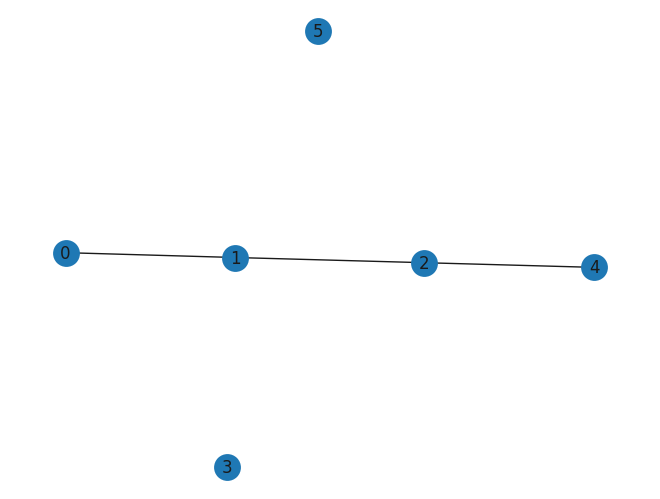

In [ ]:
#TODO : plot the reconstructed graph with nodewise regression using the rule AND
and_graph_structure = my_nodewise_regression(rule = "AND").fit(X)

nx_real = nx.from_numpy_array(and_graph_structure.T)
#We draw the initial structure
nx.draw(nx_real, with_labels=True)

**Comments:** As expected, the OR graph has more ocnnections than the AND graph. In the OR graph, points 0,1,2,4 and 3 are linked and only 5 is alone. In the AND-graph, points 0,1,2 and 4 are connected, and 3 is removed from the graph. Point 5 remains unconnected to the rest of the graph.  

# Simulations

Compare the two graph estimators for each of the following models with $p = 300$ and $n = 40, 80, 320$:

- An AR(1)-Block model. In this model the *covariance* matrix is block-diagonal with equalsized AR(1)-blocks of the form $(\Sigma_{Block})_{i, j} = 0.9^{|i−j|}$, take $30 \times 30$ blocks.
- The exponential decay model considered in Fan et al. [2009]. In this model we consider a case where no element of the concentration matrix is exactly zero. The elements of $\Theta$ are given by $\Theta_{ij} = \exp{(−2|i − j|)}$ equals essentially zero when the difference |i − j| is large.

For GLasso estimation, use cross-validation k-fold with loglikelihood loss to select the $\lambda$ penalization parameter. Evaluate your estimation using the Froebenius matrix norm. 

For Node-regression estimation, compare your edge-estimation with the binary (thresholded) covariance matrix. Evaluate your estimation using accuracy and the F1 score. 

In [44]:
#TODO

from sklearn.linear_model import Lasso

p = 300
n_values = [40, 80, 320]

Sigma_block = np.zeros((p, p))
for b in range(10): #10 blocs de 30 par 30
    idx = np.arange(b * 30, (b + 1) * 30)
    for i in idx:
        for j in idx:
            Sigma_block[i, j] = 0.9 ** abs(i - j) # matrice diagonale par blocs

Theta_block = np.linalg.inv(Sigma_block)


# Exponential Decay

i, j = np.indices((p, p))
Theta_exp = np.exp(-2 * np.abs(i - j))
Sigma_exp = np.linalg.inv(Theta_exp)

In [45]:
def frobenius_error(Theta_hat, Theta_true):
    return np.linalg.norm(Theta_hat - Theta_true, ord="fro")


def adjacency(Theta, tol=1e-8):
    A = (np.abs(Theta) > tol).astype(int)
    np.fill_diagonal(A, 0)
    return A


def accuracy_score(A_hat, A_true):
    idx = np.triu_indices_from(A_true, k=1)
    return np.mean(A_hat[idx] == A_true[idx])


def f1_score(A_hat, A_true):
    idx = np.triu_indices_from(A_true, k=1)

    y_true = A_true[idx]
    y_pred = A_hat[idx]

    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0

    return (2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0)

In [46]:
from sklearn.model_selection import KFold

def glasso_cv(X, lambda_grid, K=5):

    kf = KFold(n_splits=K, shuffle=True, random_state=123)

    cv_scores = []

    for lam in tqdm(lambda_grid):

        scores = []

        for train_idx, test_idx in kf.split(X):

            X_train = X[train_idx]
            X_test = X[test_idx]

            # Fit your own GLasso
            model = my_GLasso(lambd=lam)
            Theta_hat = model.fit(X_train)

            # Covariance matrix on validation data
            S_test = np.cov(X_test, rowvar=False)

            # Log-likelihood (up to an additive constant)
            sign, logdet = np.linalg.slogdet(Theta_hat)

            if sign <= 0:
                scores.append(-np.inf)
                continue

            score = 0.5 * (
                logdet - np.sum(S_test * Theta_hat)
            )

            scores.append(score)

        cv_scores.append(np.mean(scores))

    # Select best lambda
    best_lambda = lambda_grid[np.argmax(cv_scores)]

    # Fit final model on the whole dataset
    final_model = my_GLasso(lambd=best_lambda)
    Theta_hat = final_model.fit(X)

    return Theta_hat, best_lambda

In [47]:
import pandas as pd

def simulate_model(Sigma, Theta, model_name, n):

    A_true = adjacency(Theta)

    results = []

    lambda_grid = np.logspace(-2, 0, 10)
    
    # Generate data
    X = np.random.multivariate_normal(
        mean=np.zeros(p),
        cov=Sigma,
        size=n
    )

    # GLasso

    Theta_glasso, best_lambda = glasso_cv(
        X, lambda_grid
    )
    error = frobenius_error(
        Theta_glasso, Theta
    )

    # Nodewise Regression

    model_nodewise = my_nodewise_regression(rule='OR')
    A_nodewise = model_nodewise.fit(X)

    # Evaluation
    acc = accuracy_score(A_nodewise, A_true)
    f1 = f1_score(A_nodewise, A_true)

    results.append({
        "Model": model_name,
        "n": n,
        "Replication": b,
        "Lambda": best_lambda,
        "Frobenius": error,
        "Accuracy": acc,
        "F1": f1
    })

    return pd.DataFrame(results)

In [48]:
np.random.seed(123)

results = []

for n in n_values:

    print(f"Running n = {n}")

    results.append(
        simulate_model(
            Sigma_block, Theta_block,
            "AR1-Block", n
        )
    )

    results.append(
        simulate_model(
            Sigma_exp, Theta_exp,
            "Exponential-Decay", n
        )
    )

results = pd.concat(results, ignore_index=True)

Running n = 40


100%|██████████| 10/10 [01:14<00:00,  7.45s/it]


Running n = 80


100%|██████████| 10/10 [01:20<00:00,  8.03s/it]


Running n = 320


100%|██████████| 10/10 [01:18<00:00,  7.81s/it]


In [49]:
summary = (
    results
    .groupby(["Model", "n"])
    .agg({
        "Frobenius": ["mean", "std"],
        "Accuracy": ["mean", "std"],
        "F1": ["mean", "std"]
    })
)

print(summary)

                        Frobenius      Accuracy            F1    
                             mean std      mean std      mean std
Model             n                                              
AR1-Block         40   132.217113 NaN  0.945284 NaN  0.190633 NaN
                  80   110.216368 NaN  0.956076 NaN  0.227451 NaN
                  320   64.622732 NaN  0.963679 NaN  0.262562 NaN
Exponential-Decay 40     6.315498 NaN  0.909075 NaN  0.052949 NaN
                  80     6.998520 NaN  0.915407 NaN  0.053393 NaN
                  320    6.225295 NaN  0.915541 NaN  0.101518 NaN


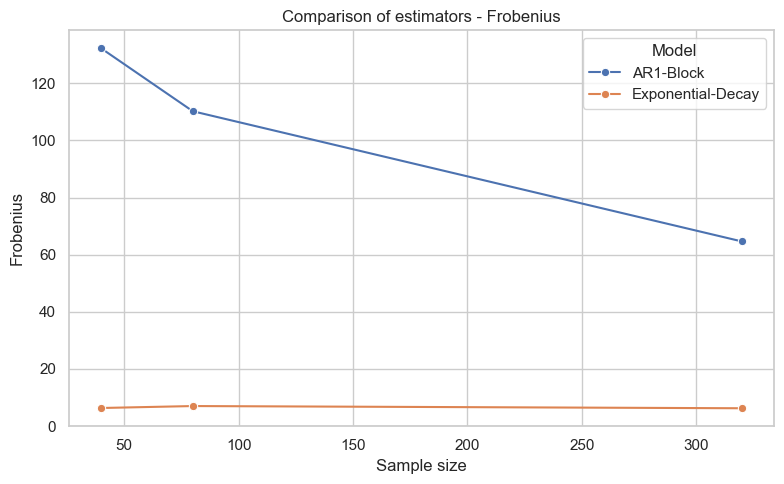

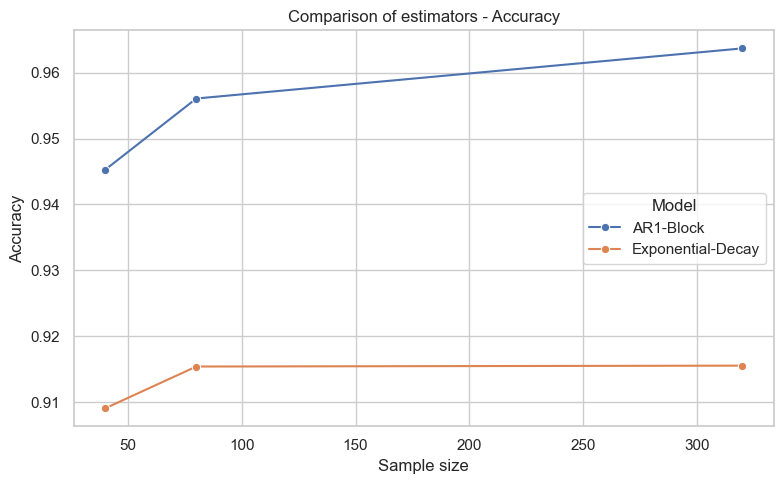

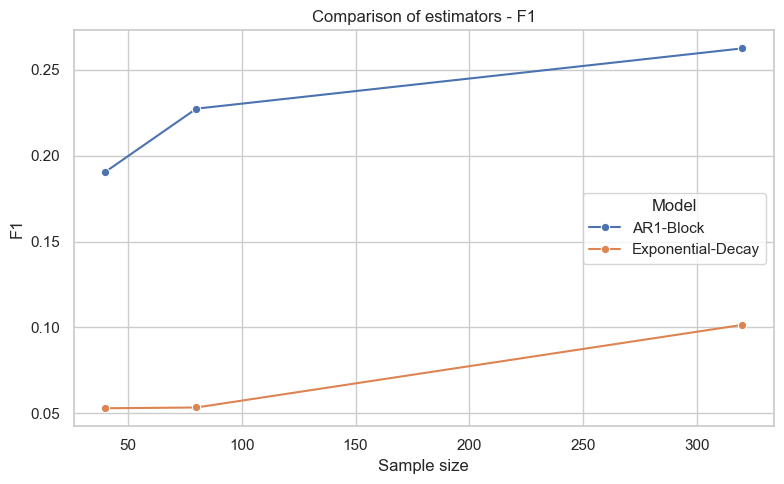

In [50]:
import seaborn as sns

sns.set_theme(style="whitegrid")

metrics = ["Frobenius", "Accuracy", "F1"]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    sns.lineplot(
        data=results,
        x="n",
        y=metric,
        hue="Model",
        marker="o",
        errorbar="sd"
    )

    plt.title(f"Comparison of estimators - {metric}")
    plt.xlabel("Sample size")
    plt.ylabel(metric)

    plt.tight_layout()
    plt.show()

**Comments:** With Glasso, the frobenius norm decreases when the number of samples increases with the AR1-Block model. For the exponential decay model, the norm is almost constant. 

With the node regression, the accuracy increases with the number of samples with both models. It is the same for the F1-score. 